## Optimizers in Deep Learning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import (
    SGD, RMSprop, Adam, AdamW
)
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(42)

In [2]:
X, y = make_moons(n_samples=2000, noise=0.25, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [3]:
def build_model(optimizer):
    model = Sequential([
        tf.keras.Input(shape=(2,)),
        Dense(64, activation="relu"),
        Dense(64, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [4]:
optimizers = {
    "SGD": lambda: SGD(learning_rate=0.01),
    "Momentum": lambda: SGD(
        learning_rate=0.01, momentum=0.9
    ),
    "Nesterov": lambda: SGD(
        learning_rate=0.01, momentum=0.9, nesterov=True
    ),
    "RMSprop": lambda: RMSprop(learning_rate=0.001),
    "Adam": lambda: Adam(learning_rate=0.001),
    "AdamW": lambda: AdamW(
        learning_rate=0.001, weight_decay=0.004
    )
}

histories = {}
results = {}

for name, optimizer_fn in optimizers.items():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(optimizer_fn())

    history = model.fit(
        X_train, y_train,
        epochs=40,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    histories[name] = history.history
    results[name] = {
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy
    }

results_df = pd.DataFrame(results).T
results_df.sort_values("Test Accuracy", ascending=False)

,Test Loss,Test Accuracy
Momentum,0.170969,0.925
Nesterov,0.169091,0.925
Adam,0.172207,0.925
RMSprop,0.171781,0.925
AdamW,0.172063,0.925
SGD,0.282304,0.890


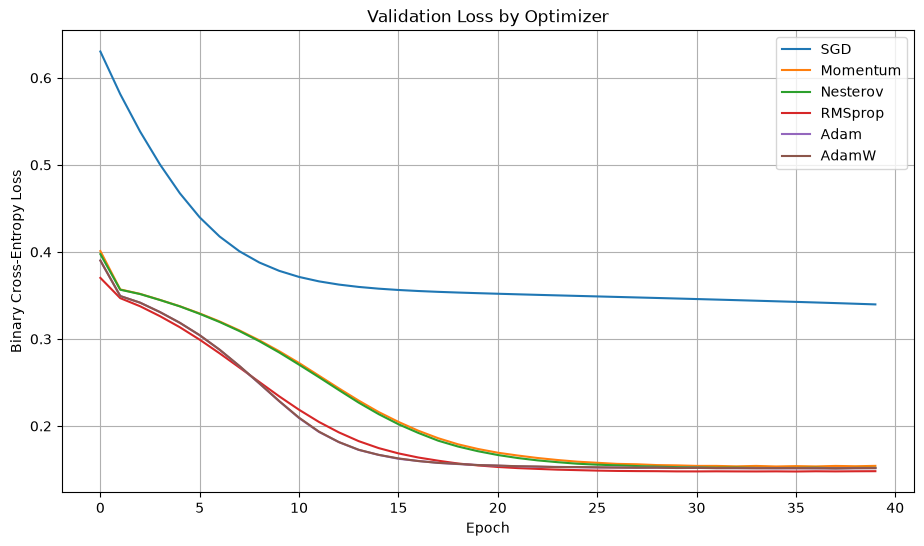

In [5]:
plt.figure(figsize=(11, 6))

for name, history in histories.items():
    plt.plot(history["val_loss"], label=name)

plt.title("Validation Loss by Optimizer")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid()
plt.show()

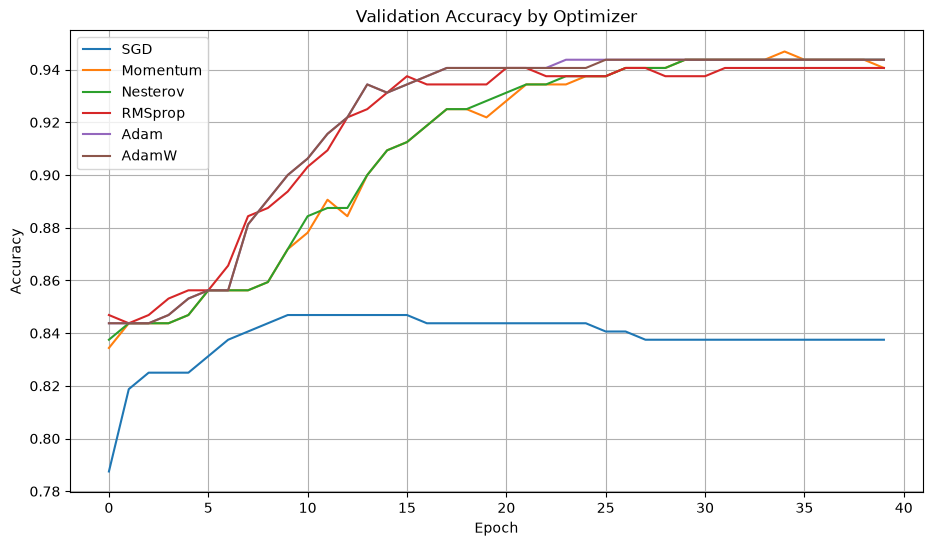

In [6]:
plt.figure(figsize=(11, 6))

for name, history in histories.items():
    plt.plot(history["val_accuracy"], label=name)

plt.title("Validation Accuracy by Optimizer")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

In [7]:
target_accuracy = 0.90

for name, history in histories.items():
    accuracies = np.array(history["val_accuracy"])
    reached = np.where(accuracies >= target_accuracy)[0]

    epoch = int(reached[0] + 1) if len(reached) else None
    print(f"{name}: epoch {epoch}")

SGD: epoch None
Momentum: epoch 15
Nesterov: epoch 15
RMSprop: epoch 11
Adam: epoch 11
AdamW: epoch 11
